In [65]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate 200 unique users and their static traits
num_users = 200
user_ids = [f"USR_{i:03d}" for i in range(1, num_users + 1)]
user_ages = np.random.randint(21, 65, size=num_users)
user_income = np.random.randint(30000, 150000, size=num_users)
user_credit = np.random.randint(300, 850, size=num_users)

# Create a user profile dictionary for easy lookup
user_profiles = {
    uid: {"Age": age, "Annual_Income": income, "Credit_Score": credit}
    for uid, age, income, credit in zip(user_ids, user_ages, user_income, user_credit)
}

# 2. Generate 1000 loan applications/records from these 200 users
num_records = 1000
record_user_ids = np.random.choice(user_ids, size=num_records)

# Define choices for categorical columns
loan_purposes = ["Home", "Auto", "Personal", "Education", "Business"]

# Lists to compile the 7 columns
data_user_id = []
data_age = []
data_income = []
data_credit = []
data_loan_amount = []
data_purpose = []
data_status = []

for uid in record_user_ids:
    profile = user_profiles[uid]
    data_user_id.append(uid)
    data_age.append(profile["Age"])
    data_income.append(profile["Annual_Income"])
    data_credit.append(profile["Credit_Score"])

    # Generate realistic loan details
    # High income allows for a higher loan amount
    max_loan = int(profile["Annual_Income"] * 0.6)
    loan_amt = np.random.randint(5000, max(15000, max_loan))
    data_loan_amount.append(loan_amt)

    # Select a loan purpose
    data_purpose.append(np.random.choice(loan_purposes))

    # Logic for approval: higher credit scores and reasonable debt-to-income ratio increase approval chances
    approval_prob = 0.1
    if profile["Credit_Score"] > 700:
        approval_prob += 0.5
    elif profile["Credit_Score"] > 600:
        approval_prob += 0.3

    if (loan_amt / profile["Annual_Income"]) < 0.3:
        approval_prob += 0.3
    elif (loan_amt / profile["Annual_Income"]) > 0.5:
        approval_prob -= 0.2

    approval_prob = np.clip(approval_prob, 0.05, 0.95)
    status = np.random.choice(["Approved", "Rejected"], p=[approval_prob, 1 - approval_prob])
    data_status.append(status)

# 3. Create the DataFrame
df = pd.DataFrame({
    "User_ID": data_user_id,
    "Age": data_age,
    "Annual_Income": data_income,
    "Credit_Score": data_credit,
    "Loan_Amount": data_loan_amount,
    "Loan_Purpose": data_purpose,
    "Loan_Status": data_status
})

# Save to CSV
df.to_csv("loan_approval_dataset.csv", index=False)

# Display summary details
print(f"Dataset Shape: {df.shape}")
print(f"Unique Users Count: {df['User_ID'].nunique()}")
print("\nFirst 5 rows of the dataset:")
print(df.head())

Dataset Shape: (1000, 7)
Unique Users Count: 199

First 5 rows of the dataset:
   User_ID  Age  Annual_Income  Credit_Score  Loan_Amount Loan_Purpose  \
0  USR_126   23          33987           824        19199     Business   
1  USR_058   60          31802           746        12214         Home   
2  USR_148   63          49738           324        23297         Home   
3  USR_200   57         130199           519        12657     Personal   
4  USR_061   26          69384           453        31685         Home   

  Loan_Status  
0    Approved  
1    Approved  
2    Rejected  
3    Rejected  
4    Rejected  


In [66]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Load the generated dataset
df_model = pd.read_csv('loan_approval_dataset.csv')

# Prepare features (X) and target (y)
# We drop 'User_ID' as it is a unique identifier, and 'Loan_Status' as it is the target
X = df_model.drop(columns=['User_ID', 'Loan_Status'])
y = df_model['Loan_Status'].map({'Approved': 1, 'Rejected': 0}) # Encode target as binary

# Identify categorical and numerical columns
num_features = ['Age', 'Annual_Income', 'Credit_Score', 'Loan_Amount']
cat_features = ['Loan_Purpose']

# Create preprocessing pipelines
num_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ]
)

# Create the pipeline with Logistic Regression
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])

# Split the dataset (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fit the model
model_pipeline.fit(X_train, y_train)

# Make predictions
y_pred = model_pipeline.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=['Rejected', 'Approved'])
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(report)
print("Confusion Matrix:")
print(conf_matrix)

Model Accuracy: 0.7500

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.77      0.83      0.80       121
    Approved       0.71      0.62      0.66        79

    accuracy                           0.75       200
   macro avg       0.74      0.73      0.73       200
weighted avg       0.75      0.75      0.75       200

Confusion Matrix:
[[101  20]
 [ 30  49]]


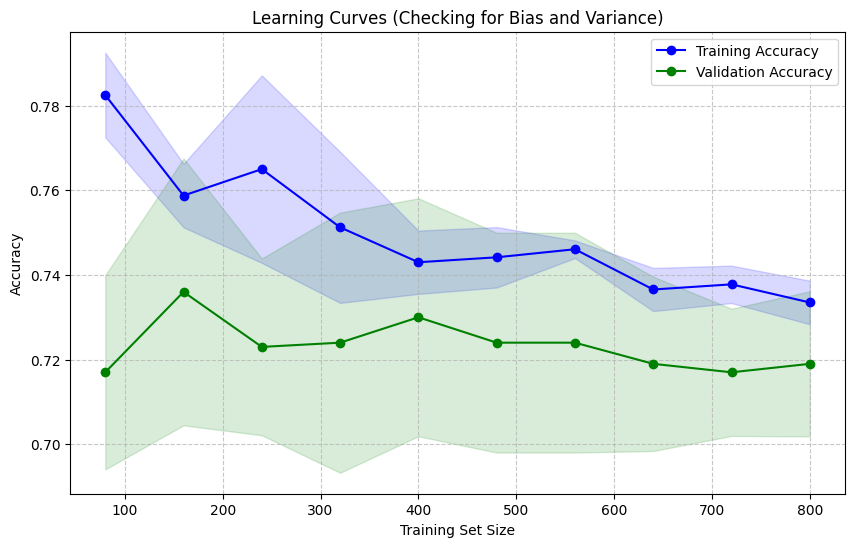

In [67]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Compute learning curves
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=model_pipeline,
    X=X,
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

# Calculate mean and standard deviation for training and validation scores
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
validation_mean = np.mean(validation_scores, axis=1)
validation_std = np.std(validation_scores, axis=1)

# Plot the learning curves
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Accuracy')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, validation_mean, 'o-', color='green', label='Validation Accuracy')
plt.fill_between(train_sizes, validation_mean - validation_std, validation_mean + validation_std, alpha=0.15, color='green')

plt.title('Learning Curves (Checking for Bias and Variance)')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

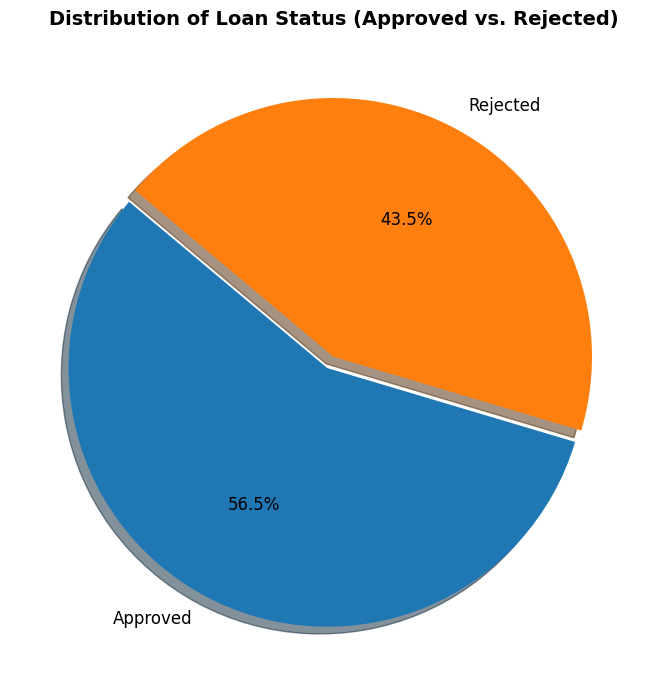

In [68]:
import matplotlib.pyplot as plt

# Define the custom category proportions
labels = ['Approved', 'Rejected']
sizes = [56.5, 43.5]
colors = ['#1f77b4', '#ff7f0e']
explode = (0.05, 0)  # slightly explode Approved

# Create the pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    sizes,
    explode=explode,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=140,
    shadow=True,
    textprops={'fontsize': 12}
)

plt.title('Distribution of Loan Status (Approved vs. Rejected)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [70]:
#@title Loan Approval Predictor { run: "auto" }

import pandas as pd
import numpy as np

# Automatically reconstruct or load the pipeline if not in global memory
if 'model_pipeline' not in globals():
    print("Model pipeline not found in memory. Reconstructing state...")
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler, OneHotEncoder
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.linear_model import LogisticRegression

    # Check if df is available in memory; if not, rebuild it dynamically
    if 'df' in globals():
        df_model = df.copy()
    else:
        print("Dataset not found in memory. Regenerating dataset...")
        np.random.seed(42)
        num_users = 200
        user_ids = [f"USR_{i:03d}" for i in range(1, num_users + 1)]
        user_ages = np.random.randint(21, 65, size=num_users)
        user_income = np.random.randint(30000, 150000, size=num_users)
        user_credit = np.random.randint(300, 850, size=num_users)
        user_profiles = {
            uid: {"Age": age, "Annual_Income": income, "Credit_Score": credit}
            for uid, age, income, credit in zip(user_ids, user_ages, user_income, user_credit)
        }
        num_records = 1000
        record_user_ids = np.random.choice(user_ids, size=num_records)
        loan_purposes = ["Home", "Auto", "Personal", "Education", "Business"]

        data_user_id, data_age, data_income, data_credit, data_loan_amount, data_purpose, data_status = [], [], [], [], [], [], []
        for uid in record_user_ids:
            profile = user_profiles[uid]
            data_user_id.append(uid)
            data_age.append(profile["Age"])
            data_income.append(profile["Annual_Income"])
            data_credit.append(profile["Credit_Score"])
            max_loan = int(profile["Annual_Income"] * 0.6)
            loan_amt = np.random.randint(5000, max(15000, max_loan))
            data_loan_amount.append(loan_amt)
            data_purpose.append(np.random.choice(loan_purposes))
            approval_prob = 0.1
            if profile["Credit_Score"] > 700:
                approval_prob += 0.5
            elif profile["Credit_Score"] > 600:
                approval_prob += 0.3
            if (loan_amt / profile["Annual_Income"]) < 0.3:
                approval_prob += 0.3
            elif (loan_amt / profile["Annual_Income"]) > 0.5:
                approval_prob -= 0.2
            approval_prob = np.clip(approval_prob, 0.05, 0.95)
            status = np.random.choice(["Approved", "Rejected"], p=[approval_prob, 1 - approval_prob])
            data_status.append(status)

        df_model = pd.DataFrame({
            "User_ID": data_user_id,
            "Age": data_age,
            "Annual_Income": data_income,
            "Credit_Score": data_credit,
            "Loan_Amount": data_loan_amount,
            "Loan_Purpose": data_purpose,
            "Loan_Status": data_status
        })
        # Save back to CSV to restore the workspace file
        df_model.to_csv("loan_approval_dataset.csv", index=False)

    X = df_model.drop(columns=['User_ID', 'Loan_Status'])
    y = df_model['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

    num_features = ['Age', 'Annual_Income', 'Credit_Score', 'Loan_Amount']
    cat_features = ['Loan_Purpose']

    num_transformer = Pipeline(steps=[('scaler', StandardScaler())])
    cat_transformer = Pipeline(steps=[('onehot', OneHotEncoder(drop='first'))])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', num_transformer, num_features),
            ('cat', cat_transformer, cat_features)
        ]
    )

    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(random_state=42))
    ])

    model_pipeline.fit(X, y)
    print("Model retrained successfully!\n")

# 1. Capture inputs from the form fields
Age = 27 #@param {type:"integer"}
Annual_Income = 60000 #@param {type:"integer"}
Credit_Score = 630 #@param {type:"slider", min:300, max:850, step:1}
Loan_Amount = 1500 #@param {type:"integer"}
Loan_Purpose = "Personal" #@param ["Home", "Auto", "Personal", "Education", "Business"]

# 2. Package inputs into a DataFrame matching the model's expected features
input_data = pd.DataFrame({
    'Age': [Age],
    'Annual_Income': [Annual_Income],
    'Credit_Score': [Credit_Score],
    'Loan_Amount': [Loan_Amount],
    'Loan_Purpose': [Loan_Purpose]
})

# 3. Use the trained pipeline to predict
prediction = model_pipeline.predict(input_data)[0]
prediction_proba = model_pipeline.predict_proba(input_data)[0]

# 4. Display results with styling
print("="*50)
print("                PREDICTION RESULTS                ")
print("="*50)
print(f"Input Attributes:")
print(f"  - Age: {Age}")
print(f"  - Annual Income: ${Annual_Income:,}")
print(f"  - Credit Score: {Credit_Score}")
print(f"  - Loan Amount: ${Loan_Amount:,}")
print(f"  - Loan Purpose: {Loan_Purpose}")
print("-"*50)

status = "APPROVED" if prediction == 1 else "REJECTED"
confidence = prediction_proba[1] if prediction == 1 else prediction_proba[0]

print(f"Result: {status}")
print(f"Probability/Confidence: {confidence:.2%}")
print("="*50)

                PREDICTION RESULTS                
Input Attributes:
  - Age: 27
  - Annual Income: $60,000
  - Credit Score: 630
  - Loan Amount: $1,500
  - Loan Purpose: Personal
--------------------------------------------------
Result: APPROVED
Probability/Confidence: 66.49%
